<a href="https://colab.research.google.com/github/KrishChothani/Computer-Vision-Using-Deep-Learning/blob/main/CVDL_PRACT_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

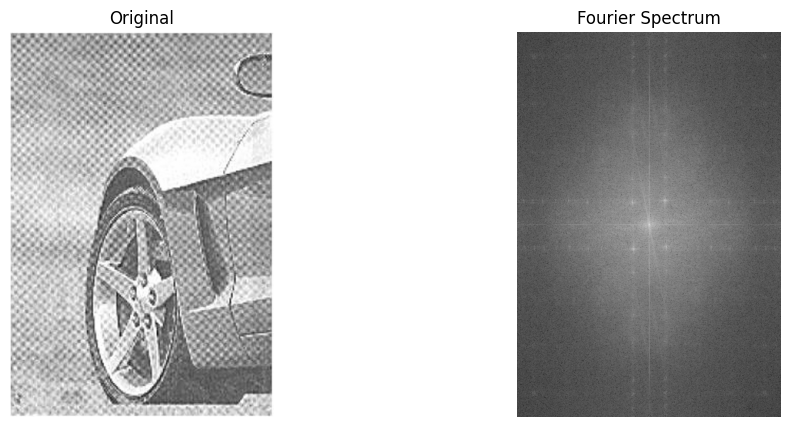

In [63]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('img111.jpg', cv2.IMREAD_GRAYSCALE)
M, N = img.shape

F = np.fft.fft2(img)
Fshift = np.fft.fftshift(F)
magnitude_spectrum = np.log(1 + np.abs(Fshift))

plt.figure(figsize=(12,5))
plt.subplot(1,2,1), plt.imshow(img, cmap='gray'), plt.title("Original"), plt.axis("off")
plt.subplot(1,2,2), plt.imshow(magnitude_spectrum, cmap='gray'), plt.title("Fourier Spectrum"), plt.axis("off")
plt.show()

u = np.arange(M)
v = np.arange(N)
V, U = np.meshgrid(v, u)
D = np.sqrt((U - M/2)**2 + (V - N/2)**2)


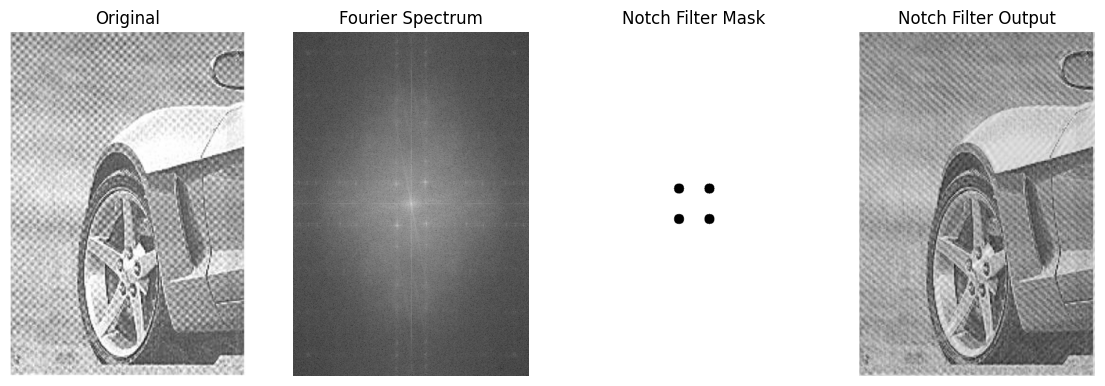

In [64]:
D0 = 10
rows, cols = img.shape
crow, ccol = rows//2 , cols//2

H = np.ones((rows, cols), np.float32)

dx, dy = 30, 30
notches = [
    (crow+dy, ccol+dx),
    (crow-dy, ccol-dx),
    (crow+dy, ccol-dx),
    (crow-dy, ccol+dx)
]

for r0, c0 in notches:
    for u in range(rows):
        for v in range(cols):
            D = np.sqrt((u-r0)**2 + (v-c0)**2)
            if D <= D0:
                H[u,v] = 0

G = Fshift * H
g = np.abs(np.fft.ifft2(np.fft.ifftshift(G)))

plt.figure(figsize=(14,5))
plt.subplot(1,4,1), plt.imshow(img, cmap='gray'), plt.title("Original"), plt.axis("off")
plt.subplot(1,4,2), plt.imshow(magnitude_spectrum, cmap='gray'), plt.title("Fourier Spectrum"), plt.axis("off")
plt.subplot(1,4,3), plt.imshow(H, cmap='gray'), plt.title("Notch Filter Mask"), plt.axis("off")
plt.subplot(1,4,4), plt.imshow(g, cmap='gray'), plt.title("Notch Filter Output"), plt.axis("off")
plt.show()

/tmp/ipython-input-1484459645.py:18: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 / (1 + (D0 / Dk)**(2*n))


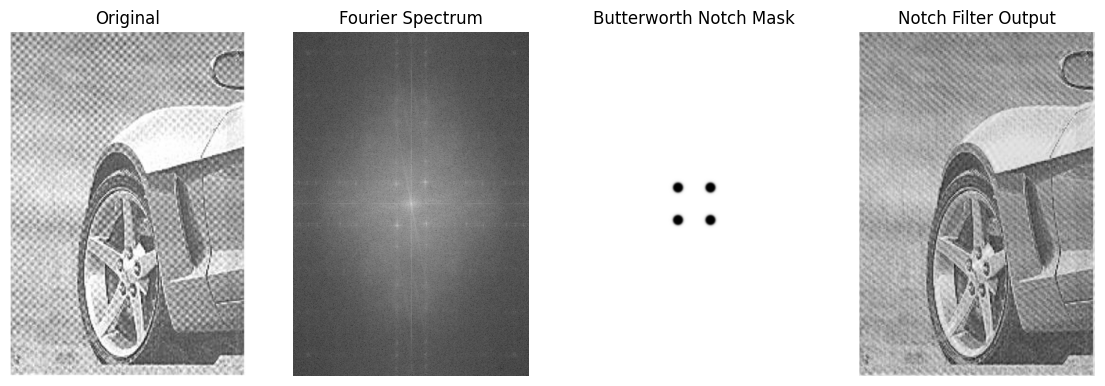

In [65]:
D0 = 10
n = 5
rows, cols = img.shape
crow, ccol = rows//2 , cols//2

H = np.ones((rows, cols), np.float32)

dx, dy = 32, 32
notches = [
    (crow+dy, ccol+dx),
    (crow-dy, ccol-dx),
    (crow+dy, ccol-dx),
    (crow-dy, ccol+dx)
]

def butterworth_notch(u, v, r0, c0, D0, n):
    Dk = np.sqrt((u-r0)**2 + (v-c0)**2)
    return 1 / (1 + (D0 / Dk)**(2*n))

for u in range(rows):
    for v in range(cols):
        for r0, c0 in notches:
            H[u,v] *= butterworth_notch(u, v, r0, c0, D0, n)

G = Fshift * H
g = np.abs(np.fft.ifft2(np.fft.ifftshift(G)))

plt.figure(figsize=(14,5))
plt.subplot(1,4,1), plt.imshow(img, cmap='gray'), plt.title("Original"), plt.axis("off")
plt.subplot(1,4,2), plt.imshow(magnitude_spectrum, cmap='gray'), plt.title("Fourier Spectrum"), plt.axis("off")
plt.subplot(1,4,3), plt.imshow(H, cmap='gray'), plt.title("Butterworth Notch Mask"), plt.axis("off")
plt.subplot(1,4,4), plt.imshow(g, cmap='gray'), plt.title("Notch Filter Output"), plt.axis("off")
plt.show()

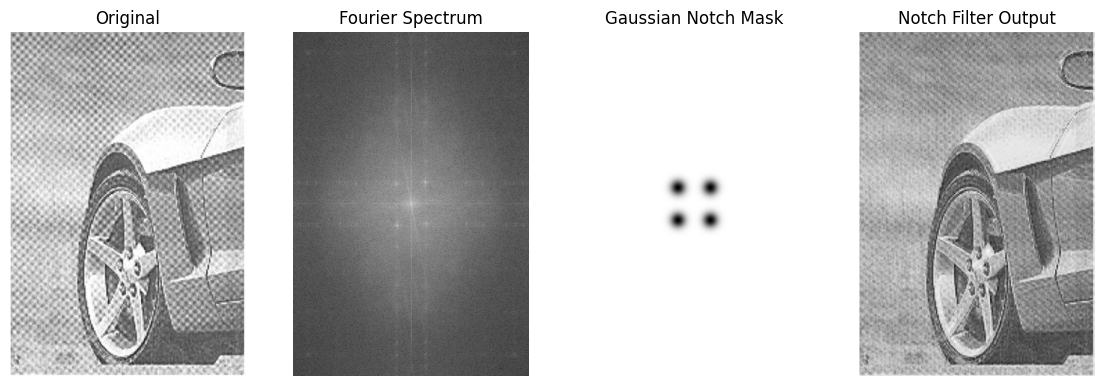

In [66]:
import numpy as np
import matplotlib.pyplot as plt

D0 = 10
rows, cols = img.shape
crow, ccol = rows//2 , cols//2

H = np.ones((rows, cols), np.float32)

dx, dy = 32, 32
notches = [
    (crow+dy, ccol+dx),
    (crow-dy, ccol-dx),
    (crow+dy, ccol-dx),
    (crow-dy, ccol+dx)
]

for r0, c0 in notches:
    for u in range(rows):
        for v in range(cols):
            Dk = np.sqrt((u-r0)**2 + (v-c0)**2)
            H[u,v] *= 1 - np.exp(-(Dk**2) / (2*(D0**2)))

G = Fshift * H
g = np.abs(np.fft.ifft2(np.fft.ifftshift(G)))

plt.figure(figsize=(14,5))
plt.subplot(1,4,1), plt.imshow(img, cmap='gray'), plt.title("Original"), plt.axis("off")
plt.subplot(1,4,2), plt.imshow(magnitude_spectrum, cmap='gray'), plt.title("Fourier Spectrum"), plt.axis("off")
plt.subplot(1,4,3), plt.imshow(H, cmap='gray'), plt.title("Gaussian Notch Mask"), plt.axis("off")
plt.subplot(1,4,4), plt.imshow(g, cmap='gray'), plt.title("Notch Filter Output"), plt.axis("off")
plt.show()

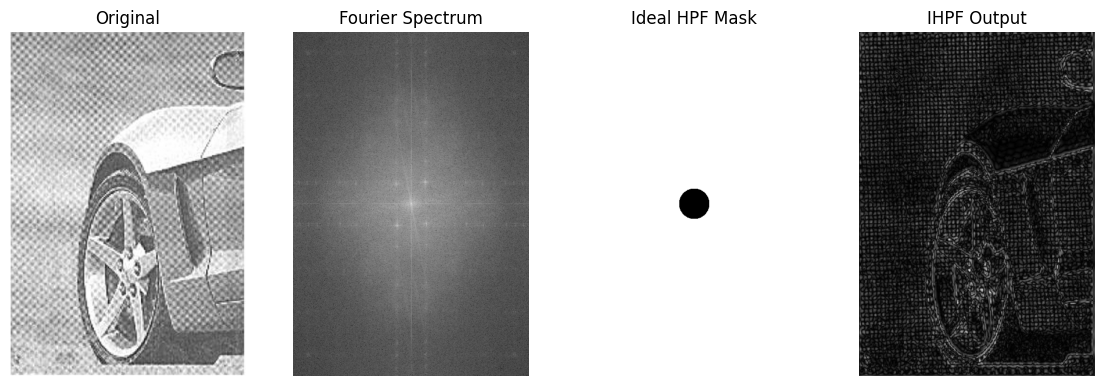

In [70]:
D0 = 30

# Recalculate D with the correct shape
M, N = img.shape
u = np.arange(M)
v = np.arange(N)
V, U = np.meshgrid(v, u)
D = np.sqrt((U - M/2)**2 + (V - N/2)**2)

H = (D >= D0).astype(np.float32)
G = Fshift * H
g = np.abs(np.fft.ifft2(np.fft.ifftshift(G)))

plt.figure(figsize=(14,5))
plt.subplot(1,4,1), plt.imshow(img, cmap='gray'), plt.title("Original"), plt.axis("off")
plt.subplot(1,4,2), plt.imshow(magnitude_spectrum, cmap='gray'), plt.title("Fourier Spectrum"), plt.axis("off")
plt.subplot(1,4,3), plt.imshow(H, cmap='gray'), plt.title("Ideal HPF Mask"), plt.axis("off")
plt.subplot(1,4,4), plt.imshow(g, cmap='gray'), plt.title("IHPF Output"), plt.axis("off")
plt.show()

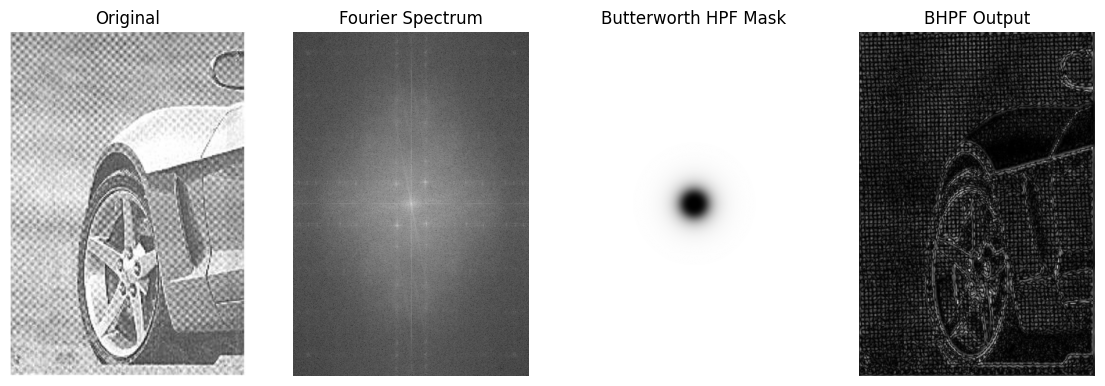

In [72]:
D0 = 30
n = 2
H = 1 - (1 / (1 + (D/D0)**(2*n)))
G = Fshift * H
g = np.abs(np.fft.ifft2(np.fft.ifftshift(G)))

plt.figure(figsize=(14,5))
plt.subplot(1,4,1), plt.imshow(img, cmap='gray'), plt.title("Original"), plt.axis("off")
plt.subplot(1,4,2), plt.imshow(magnitude_spectrum, cmap='gray'), plt.title("Fourier Spectrum"), plt.axis("off")
plt.subplot(1,4,3), plt.imshow(H, cmap='gray'), plt.title("Butterworth HPF Mask"), plt.axis("off")
plt.subplot(1,4,4), plt.imshow(g, cmap='gray'), plt.title("BHPF Output"), plt.axis("off")
plt.show()


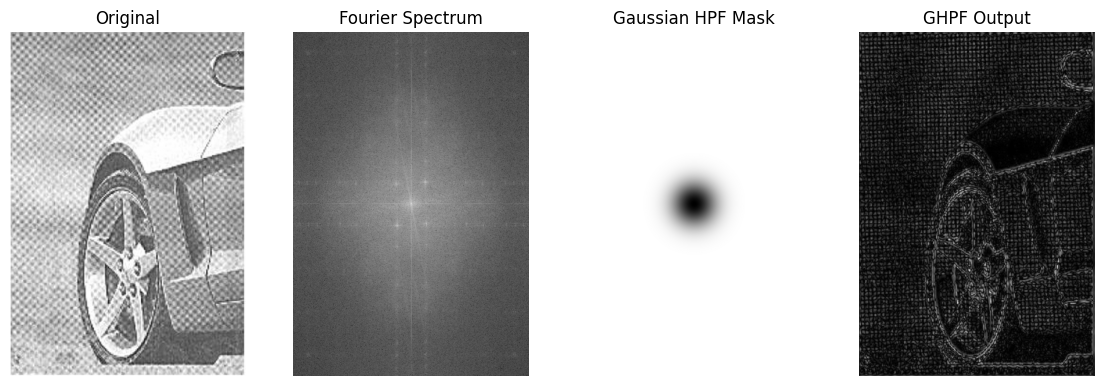

In [73]:
D0 = 30
H = 1 - np.exp(-(D**2) / (2*(D0**2)))
G = Fshift * H
g = np.abs(np.fft.ifft2(np.fft.ifftshift(G)))

plt.figure(figsize=(14,5))
plt.subplot(1,4,1), plt.imshow(img, cmap='gray'), plt.title("Original"), plt.axis("off")
plt.subplot(1,4,2), plt.imshow(magnitude_spectrum, cmap='gray'), plt.title("Fourier Spectrum"), plt.axis("off")
plt.subplot(1,4,3), plt.imshow(H, cmap='gray'), plt.title("Gaussian HPF Mask"), plt.axis("off")
plt.subplot(1,4,4), plt.imshow(g, cmap='gray'), plt.title("GHPF Output"), plt.axis("off")
plt.show()


In [ ]:
`